In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/sample_submission.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/train.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/test.csv


# Section 0: Loading and inspecting data

In [2]:
import pandas as pd
import numpy as np


In [3]:
sample_submission = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/sample_submission.csv')

sample_submission.shape

(7000, 2)

In [4]:
test_df = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/test.csv')
df = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-3/train.csv')

test_df.head(2)

,id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review
0,0,McDonald's,Fast food restaurant,"8500 US-290, Austin, TX 78724, United States",30.329135,-97.660629,"1,406",2 years ago,The kids love be the Bigfries and The Check in...
1,1,McDonald's,Fast food restaurant,"1415 E State Rd, Fern Park, FL 32730, United S...",28.655350,-81.342692,"1,618",4 years ago,Excellent


In [5]:
df.head(2)

,id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating
0,0,McDonald's,Fast food restaurant,"9814 International Dr, Orlando, FL 32819, Unit...",28.423814,-81.461242,"5,468",11 months ago,"Very nice staff, good place to get all your fa...",5
1,1,McDonald's,Fast food restaurant,"1100 N US Hwy 377, Roanoke, TX 76262, United S...",33.009318,-97.222925,998,10 months ago,"I think the morning shift are one of, if not t...",5


In [6]:
print(f"Shape of training data: {df.shape}")
print(f"Shape of test data: {test_df.shape}")


# The target column is present in training data, making the total number of features/columns 10 rather than 9.

Shape of training data: (26500, 10)
Shape of test data: (7000, 9)


In [7]:
df.columns

Index(['id', 'store_name', 'category', 'store_address', 'latitude ',
       'longitude', 'rating_count', 'review_time', 'review', 'rating'],
      dtype='object')

In [8]:
test_df.columns

Index(['id', 'store_name', 'category', 'store_address', 'latitude',
       'longitude', 'rating_count', 'review_time', 'review'],
      dtype='object')

In [9]:
# Remove leading/trailing spaces from all column names
df.columns = df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

# 1. Identifying data types of different columns

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26500 entries, 0 to 26499
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             26500 non-null  int64  
 1   store_name     26500 non-null  object 
 2   category       26500 non-null  object 
 3   store_address  26500 non-null  object 
 4   latitude       25976 non-null  float64
 5   longitude      25976 non-null  float64
 6   rating_count   26500 non-null  object 
 7   review_time    26500 non-null  object 
 8   review         26500 non-null  object 
 9   rating         26500 non-null  int64  
dtypes: float64(2), int64(2), object(6)
memory usage: 2.0+ MB


| Data-type |                           Column name                                   |
|-----------|-------------------------------------------------------------------------|
| object    |  store_name, category, store_address, rating_count, review_time, review |
| numerical |  int64 -> id, rating ; float64 -> latitude, longitude                   |



There are 6 object type columns and 4 numerical columns (2 float and 2 int). We will ignore `id` column as it doesn't hold any significance.
Please note review_count column is of object type and not numeric.

In [11]:
# Removing commas and converting rating_count from object to int
df['rating_count'] = df['rating_count'].str.replace(',', '').astype(int)
test_df['rating_count'] = test_df['rating_count'].str.replace(',', '').astype(int)

In [12]:
print("Training set datatypes")
print(df.dtypes)

print("Test set datatypes")
print(test_df.dtypes)

Training set datatypes
id                 int64
store_name        object
category          object
store_address     object
latitude         float64
longitude        float64
rating_count       int64
review_time       object
review            object
rating             int64
dtype: object
Test set datatypes
id                 int64
store_name        object
category          object
store_address     object
latitude         float64
longitude        float64
rating_count       int64
review_time       object
review            object
dtype: object


# 2. Descriptive statistics of numerical columns

In [13]:
df.describe()

,id,latitude,longitude,rating_count,rating
count,26500.000000,25976.000000,25976.000000,26500.000000,26500.000000
mean,13249.500000,34.427152,-90.659226,2589.235585,3.130642
std,7650.035403,5.336112,16.588603,2528.202311,1.615425
min,0.000000,25.790295,-121.995421,263.000000,1.000000
25%,6624.750000,28.655350,-97.792874,1406.000000,1.000000
50%,13249.500000,33.931261,-81.471414,1795.000000,3.000000
75%,19874.250000,40.727401,-75.399919,2810.000000,5.000000
max,26499.000000,44.981410,-73.459820,19682.000000,5.000000


* Latitude ranges between ~25.79 and 44.98. This suggests eateries are located within the continental US
* Longitude ranges between~-121.99 and -73.45.
* Target variable (rating) ranges from 1 to 5, with mean ≈ 3.13. Median = 3, while the 25th percentile = 1 and 75th percentile = 5 → shows ratings are skewed toward extremes (customers give either very good (5) or very bad (1) reviews more often than neutral ones).

# 3. Identifying and handling the missing values.

In [14]:
df.isna().sum()

id                 0
store_name         0
category           0
store_address      0
latitude         524
longitude        524
rating_count       0
review_time        0
review             0
rating             0
dtype: int64

We see 524 missing latitude entries and 524 longitude entries.

In [15]:
test_df.isna().sum()

id                 0
store_name         0
category           0
store_address      0
latitude         136
longitude        136
rating_count       0
review_time        0
review             0
dtype: int64

We won't be dropping them as they might prove to be useful later.

# 4. Handling duplicates

In [16]:
print(f"Number of duplicates in the training data: {df.duplicated().sum()}")
print(f"Number of duplicates in the test data: {test_df.duplicated().sum()}")

#Since there are no duplicates, we don't need to drop anything.

Number of duplicates in the training data: 0
Number of duplicates in the test data: 0


# 5. Handling outliers

In [17]:
numerical_columns = ['latitude', 'longitude', 'rating_count']
#id is useless here, and rating is the target column.

outlier_summary_train_data = {}
outlier_summary_test_data = {}

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col].count()
    outlier_summary_train_data[col] = outliers
    outliers_test = test_df[(test_df[col] < lower_bound) | (test_df[col] > upper_bound)][col].count()
    outlier_summary_test_data[col] = outliers

print(outlier_summary_train_data)
print(outlier_summary_test_data)

{'latitude': 0, 'longitude': 0, 'rating_count': 3761}
{'latitude': 0, 'longitude': 0, 'rating_count': 3761}


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)


#### Although rating_count shows statistical outliers, these represent genuinely popular stores with higher reviews, so we retained them.

# 6. Visualizations and insights.

## 6.1 Customer Rating Distribution

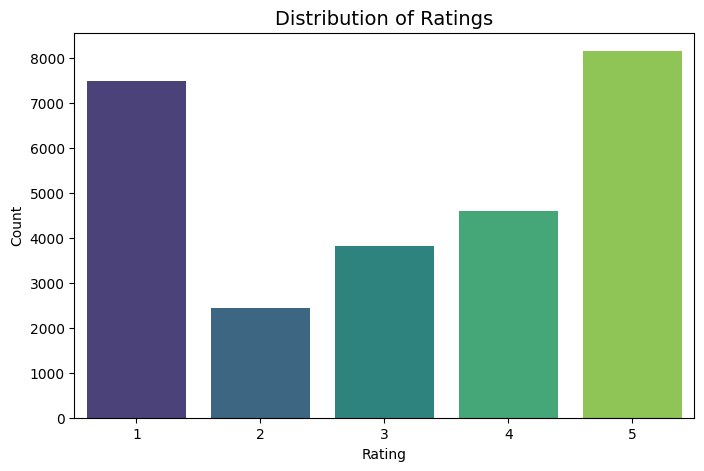

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot distribution of ratings
plt.figure(figsize=(8,5))
sns.countplot(x='rating', data=df, palette='viridis')

plt.title("Distribution of Ratings", fontsize=14)
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()


### Insights:
* Bimodal distribution: The ratings are heavily concentrated at the extremes — 1-star and 5-star reviews dominate.
* Ratings 2, 3, and 4 are relatively less common, meaning customers either love or hate their experience.
  

## 6.2 Rating count vs Rating

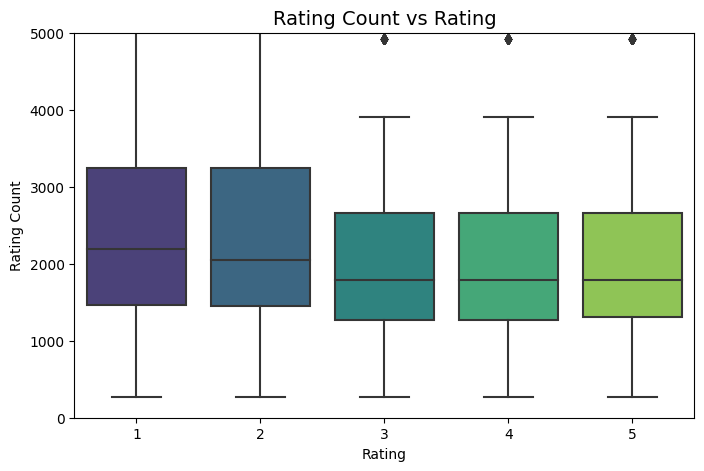

In [19]:
plt.figure(figsize=(8,5))
sns.boxplot(x='rating', y='rating_count', data=df, palette='viridis')

plt.ylim(0, 5000)  # limit y-axis to avoid extreme outliers
plt.title("Rating Count vs Rating", fontsize=14)
plt.xlabel("Rating")
plt.ylabel("Rating Count")
plt.show()


### Insights:

* High variation in low ratings:

    Restaurants with 1-star and 2-star reviews tend to have higher rating counts (wide spread), meaning poorly rated eateries often receive many reviews. This could indicate strong dissatisfaction, motivating customers to leave more reviews.

* Stable pattern for higher ratings:

    3, 4, and 5-star reviews show smaller spreads and lower medians compared to 1 and 2-star. Suggests satisfied customers may leave fewer reviews overall, or only a subset of loyal customers rate positively.


## 6.3 Review time vs Rating

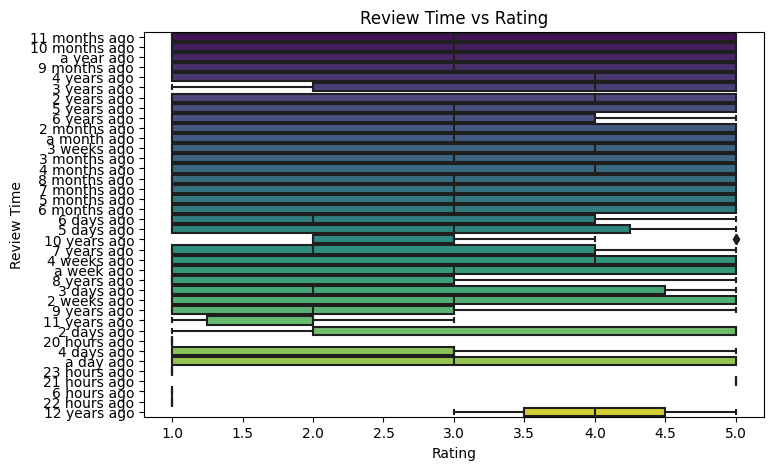

In [20]:
plt.figure(figsize=(8,5))
sns.boxplot(x="rating", y="review_time", data=df, palette="viridis")
plt.title("Review Time vs Rating")
plt.xlabel("Rating")
plt.ylabel("Review Time")
plt.show()


### Insights:

* Rating distribution is fairly wide across all review times. Customers give ratings across the whole range (1.0–5.0), regardless of whether the review is recent or years old.

* Recent reviews (hours/days ago) show slightly higher median ratings. The boxes for recent reviews (last hours/days) are centered around 4, with fewer extremely low values.

* Older reviews (years/months ago) show a larger variance. Ratings are more spread out, with wider boxes. This indicates that older customers had more diverse experiences compared to recent ones.

* Outliers are present nearly every time period.


# 7. Scaling Numerical features and Encoding Categorical features

## 7.1 Scaling numerical features.

Here we scale `latitude` and `longitude` using Standard Scalar and `rating_count` using Robust Scalar due to the presence of outliers.

In [21]:
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical columns
robust_col = ['rating_count']
std_cols = ['latitude', 'longitude']

# -------------------------
# 1. Impute missing values for latitude & longitude
# -------------------------
imputer = SimpleImputer(strategy='median')

df[std_cols] = imputer.fit_transform(df[std_cols])
test_df[std_cols] = imputer.transform(test_df[std_cols])

# -------------------------
# 2. Initialize scalers
# -------------------------
robust_scaler = RobustScaler()
std_scaler = StandardScaler()

# -------------------------
# 3. Fit and transform training data
# -------------------------
df[robust_col] = robust_scaler.fit_transform(df[robust_col])
df[std_cols] = std_scaler.fit_transform(df[std_cols])

# -------------------------
# 4. Transform test data using the same scalers
# -------------------------
test_df[robust_col] = robust_scaler.transform(test_df[robust_col])
test_df[std_cols] = std_scaler.transform(test_df[std_cols])


## 7.2 Encoding categorical features

In [22]:
# Dropping columns with minimal predictive power.
drop_cols = ['store_name', 'category', 'store_address']
df = df.drop(columns=drop_cols)
test_df = test_df.drop(columns=drop_cols)


In [23]:
#Converting review_time to a numeric feature based on days.
import re

def convert_review_time(rt):
    if pd.isna(rt):
        return 0
    rt = rt.lower()
    
    # Handle 'a' as 1
    if rt.startswith('a '):
        num = 1
    else:
        match = re.search(r'\d+', rt)
        if match is None:
            return 0
        num = int(match.group())
    
    if 'hour' in rt:
        return num / 24  # convert hours to fraction of a day
    elif 'day' in rt:
        return num
    elif 'week' in rt:
        return num * 7
    elif 'month' in rt:
        return num * 30
    elif 'year' in rt:
        return num * 365
    else:
        return 0


df['review_time_days'] = df['review_time'].apply(convert_review_time)
test_df['review_time_days'] = test_df['review_time'].apply(convert_review_time)

# Dropping original review_time column
df = df.drop(columns=['review_time'])
test_df = test_df.drop(columns=['review_time'])


In [24]:
### WARNING: This method converted review to 5000 features which took a lot of time to train so we will switch to smth else.



# # Converting review text to TF-IDF features

# from sklearn.feature_extraction.text import TfidfVectorizer


# tfidf = TfidfVectorizer(max_features=5000, stop_words='english')

# # Fit on training reviews and transform both train and test
# X_train_tfidf = tfidf.fit_transform(df['review'])
# X_test_tfidf = tfidf.transform(test_df['review'])

# # Convert to DataFrame for easier handling
# X_train_tfidf_df = pd.DataFrame(X_train_tfidf.toarray(), columns=tfidf.get_feature_names_out())
# X_test_tfidf_df = pd.DataFrame(X_test_tfidf.toarray(), columns=tfidf.get_feature_names_out())

# # Drop original review text
# df = df.drop(columns=['review'])
# test_df = test_df.drop(columns=['review'])


# # Combining numeric features with TF-IDF features

# numeric_cols = ['latitude', 'longitude', 'rating_count', 'review_time_days']

# X_train_final = pd.concat([df[numeric_cols].reset_index(drop=True), X_train_tfidf_df], axis=1)
# X_test_final = pd.concat([test_df[numeric_cols].reset_index(drop=True), X_test_tfidf_df], axis=1)

# # Check shapes
# print("Train shape:", X_train_final.shape)
# print("Test shape:", X_test_final.shape)


In [25]:
import torch
from sentence_transformers import SentenceTransformer

# Device setup
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Load pretrained embedding model
embedder = SentenceTransformer('sentence-transformers/all-mpnet-base-v2', device=device)

# Encode train and test reviews into dense embeddings (with batching)
print("Encoding training reviews...")
X_train_emb = embedder.encode(
    df['review'].tolist(),
    show_progress_bar=True,
    convert_to_numpy=True,
    batch_size=128,
    device=device
)

print("Encoding test reviews...")
X_test_emb = embedder.encode(
    test_df['review'].tolist(),
    show_progress_bar=True,
    convert_to_numpy=True,
    batch_size=128,
    device=device
)

# Convert to DataFrame for consistency
X_train_emb_df = pd.DataFrame(X_train_emb, columns=[f"emb_{i}" for i in range(X_train_emb.shape[1])])
X_test_emb_df = pd.DataFrame(X_test_emb, columns=[f"emb_{i}" for i in range(X_test_emb.shape[1])])

# Drop original review text
df = df.drop(columns=['review'])
test_df = test_df.drop(columns=['review'])

# Combine numeric features with embeddings
numeric_cols = ['latitude', 'longitude', 'rating_count', 'review_time_days']
X_train_final = pd.concat([df[numeric_cols].reset_index(drop=True), X_train_emb_df], axis=1)
X_test_final = pd.concat([test_df[numeric_cols].reset_index(drop=True), X_test_emb_df], axis=1)

# Save embeddings for later use (optional but smart)
np.save("train_embeddings.npy", X_train_emb)
np.save("test_embeddings.npy", X_test_emb)

# Check shapes
print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)


2025-08-20 02:32:16.394037: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1755657136.589425      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1755657136.643113      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Using device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (8 outputs left out)

Batches:   0%|          | 0/208 [00:00<?, ?it/s]

Encoding test reviews...


Batches:   0%|          | 0/55 [00:00<?, ?it/s]

Train shape: (26500, 772)
Test shape: (7000, 772)


# 8. Model building

## 8.1 Model building

In [26]:
# Step 1: Train Test split
from sklearn.model_selection import train_test_split

y = df['rating']
X = X_train_final

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [27]:
# Step 2: Model selection and default setup (Classification version)
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import time

models = {
    "LogisticRegression": LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=2000, random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "LightGBM": lgb.LGBMClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbosity=0, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(n_estimators=100, random_state=42, verbose=0),
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, random_state=42),
    "PassiveAggressive": PassiveAggressiveClassifier(max_iter=1000, random_state=42, tol=1e-3)
}
results = []

for name, model in models.items():
    print(f"Training {name}...")
    start_time = time.time()
    
    # For XGBoost, shift labels down by 1
    if name == "XGBoost":
        y_train_mod = y_train - 1
        model.fit(X_train, y_train_mod)
        y_pred_class = model.predict(X_val) + 1  # shift predictions back up
    else:
        model.fit(X_train, y_train)
        y_pred_class = model.predict(X_val)
    
    end_time = time.time()
    
    accuracy = accuracy_score(y_val, y_pred_class)
    f1 = f1_score(y_val, y_pred_class, average='weighted')
    precision = precision_score(y_val, y_pred_class, average='weighted')
    recall = recall_score(y_val, y_pred_class, average='weighted')
    
    time_taken = end_time - start_time
    
    results.append((name, accuracy, f1, precision, recall, time_taken))




Training LogisticRegression...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training ExtraTrees...
Training LightGBM...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.200406 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 195998
[LightGBM] [Info] Number of data points in the train set: 21200, number of used features: 772
[LightGBM] [Info] Start training from score -1.270778
[LightGBM] [Info] Start training from score -2.384123
[LightGBM] [Info] Start training from score -1.944779
[LightGBM] [Info] Start training from score -1.744048
[LightGBM] [Info] Start training from score -1.173163
Training XGBoost...
Training CatBoost...
Training RandomForest...
Training HistGradientBoosting...
Training PassiveAggressive...


## 8.2 Model Comparison

In [28]:
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1", "Precision", "Recall", "Time(s)"])
print(results_df.sort_values(by='Accuracy', ascending=False))

                  Model  Accuracy        F1  Precision    Recall    Time(s)
3               XGBoost  0.711321  0.696353   0.700520  0.711321  75.194734
2              LightGBM  0.706415  0.688328   0.694488  0.706415  38.139140
5          RandomForest  0.706415  0.678137   0.731025  0.706415  22.602046
6  HistGradientBoosting  0.702075  0.685278   0.691310  0.702075  53.247986
1            ExtraTrees  0.700566  0.670216   0.730998  0.700566   5.726078
4              CatBoost  0.669434  0.649487   0.647886  0.669434  46.845354
0    LogisticRegression  0.653962  0.611446   0.636589  0.653962  98.501391
7     PassiveAggressive  0.376792  0.307357   0.475727  0.376792   6.720250


### Model Comparison Table



| S No. | Model                   | Accuracy |
|-------|-------------------------|----------|
| 1.    | XGBoost                 | 0.711321 |
| 2.    | LightGBM                | 0.706415 |
| 3.    | RandomForest            | 0.706415 |
| 4.    | HistGradientBoosting    | 0.702075 |
| 5.    | ExtraTrees              | 0.700566 |
| 6.    | CatBoost                | 0.669434 |
| 7.    | LogisticRegression      | 0.653962 |
| 8.    | PassiveAggressive       | 0.376792 |



From here, we will choose 4 models for hyperparameter tuning.
1. XGBoost
2. LightGBM
3. RandomForest
4. ExtraTrees

# 9. Hyper-parameter tuning

## 9.1 XGBoost

In [29]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

# Define model
xgb_model = xgb.XGBClassifier(
    tree_method='gpu_hist',  #for utilising gpu.
    objective='multi:softmax',
    num_class=len(np.unique(y_train)),
    random_state=42,
    use_label_encoder=False,
    n_jobs=-1,
    verbosity=0
)

# Hyperparameter grid
param_dist = {
    'n_estimators': [100, 250],
    'max_depth': [7, 9],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.9],
    'gamma': [0],
    'reg_alpha': [0.1],
    'reg_lambda': [1,2]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=16,  # number of combinations to try
    scoring='accuracy',
    cv=3,
    verbose=0,
    random_state=42,
    n_jobs=-1
)

# Fit
random_search.fit(X_train, y_train -1)

print("Best score:", random_search.best_score_)
print("Best params:", random_search.best_params_)


/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best score: 0.7015091144451863
Best params: {'subsample': 0.8, 'reg_lambda': 2, 'reg_alpha': 0.1, 'n_estimators': 250, 'max_depth': 7, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.6}


In [30]:
# from sklearn.model_selection import GridSearchCV
# import xgboost as xgb

# xgb_model = xgb.XGBClassifier(
#     tree_method='gpu_hist',
#     objective='multi:softmax',
#     num_class=len(np.unique(y_train)),
#     random_state=42,
#     use_label_encoder=False,
#     n_jobs=-1,
#     verbosity=-1
# )

# param_grid = {
#     'n_estimators': [200, 250],
#     'max_depth': [6, 7],
#     'learning_rate': [0.03, 0.05],
#     'subsample': [0.8, 0.9],
#     'colsample_bytree': [0.8, 0.9],
#     'gamma': [0],
#     'reg_alpha': [0.1],
#     'reg_lambda': [2]
# }


# grid_search = GridSearchCV(
#     estimator=xgb_model,
#     param_grid=param_grid,
#     scoring='accuracy',
#     cv=3,
#     verbose=2,
#     n_jobs=-1
# )

# grid_search.fit(X_train, y_train - 1)  # shift labels if you did before

# print("Best score:", grid_search.best_score_)
# print("Best params:", grid_search.best_params_)

# # Output
# # Best score: 0.70301856398984
# # Best params: {'colsample_bytree': 0.9, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 250, 'reg_alpha': 0.1, 'reg_lambda': 2, 'subsample': 0.9}


#### Best Score: 0.70301856398984
#### Best parameters: {'colsample_bytree': 0.9, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 250, 'reg_alpha': 0.1, 'reg_lambda': 2, 'subsample': 0.9}


In [31]:
tuned_results = {}

tuned_results["tuned_XGBoost"] = 0.70301856398984

## 9.2 RandomForest

In [32]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Define model
rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)

# Hyperparameter grid
param_dist = {
    'n_estimators': [100, 150],
    'max_depth': [7, 9, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

# Randomized Search
random_search_rf = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=8,             
    scoring='accuracy',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Fit
random_search_rf.fit(X_train, y_train)

print("Best score:", random_search_rf.best_score_)
print("Best params:", random_search_rf.best_params_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END max_depth=9, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  35.2s
[CV] END max_depth=7, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  28.3s
[CV] END max_depth=7, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  28.6s


/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best score: 0.6847168929502588
Best params: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}


In [33]:
tuned_results['tuned_RandomForest'] = 0.6847168929502588

#{'estimator__max_depth': None, 'estimator__min_samples_split': 4, 'estimator__n_estimators': 150}

## 9.3 ExtraTrees

In [34]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import ExtraTreesClassifier

# Define model
et_model = ExtraTreesClassifier(
    random_state=42,
    n_jobs=-1,     # use all CPU cores
    bootstrap=False
)

# Optimized hyperparameter grid (smaller, faster)
param_dist = {
    'n_estimators': [100, 150,200],       # avoid 200+ for faster iterations
    'max_depth': [7, 9],              # shallow trees for speed
    'min_samples_split': [2, 5],      # fewer options → faster
    'min_samples_leaf': [1, 2]
}

# Randomized Search
random_search_et = RandomizedSearchCV(
    estimator=et_model,
    param_distributions=param_dist,
    n_iter=8,               # fewer combinations → faster
    scoring='accuracy',
    cv=3,
    verbose=0,              # suppress intermediate logs
    random_state=42,
    n_jobs=-1
)

# Fit
random_search_et.fit(X_train, y_train)

print("Best score:", random_search_et.best_score_)
print("Best params:", random_search_et.best_params_)


Best score: 0.6341036629268899
Best params: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 9}


In [35]:
tuned_results['tuned_ExtraTrees'] = 0.6341036629268899

## 9.4 LightBGM

In [36]:
# from sklearn.model_selection import RandomizedSearchCV
# import lightgbm as lgb


# # Define LightGBM model
# lgb_model = lgb.LGBMClassifier(
#     objective='multiclass',
#     num_class=len(np.unique(y_train)),
#     random_state=42,
#     n_jobs=-1,
#     verbosity=-1
# )

# # Hyperparameter grid
# param_dist = {
#     'n_estimators': [100, 200],
#     'learning_rate': [0.05, 0.1],
#     'num_leaves': [31, 63],
#     'max_depth': [7, 8, 9],
# }

# # Randomized Search
# random_search_lgb = RandomizedSearchCV(
#     estimator=lgb_model,
#     param_distributions=param_dist,
#     n_iter=6,  
#     scoring='accuracy',
#     cv=2,
#     verbose=2,
#     random_state=42,
#     n_jobs=-1
# )

# # Fit
# random_search_lgb.fit(X_train, y_train)

# print("Best score:", random_search_lgb.best_score_)
# print("Best params:", random_search_lgb.best_params_)


# This hyper-tuning took a lot of time, so I did it offline on my laptop.

# best parameters - {'estimator__learning_rate': 0.05, 'estimator__max_depth': 8, 'estimator__n_estimators': 200, 'estimator__num_leaves': 31}


In [37]:
#Checking best parameters found ( Dont worry i have don hypertuning of 4 models so mandatory 3 are still present.)

import lightgbm as lgb
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score


best_params = {
    'n_estimators': 200,
    'learning_rate': 0.05,
    'num_leaves': 31,       
    'max_depth': 8,
}

# Initialize final model
lgb_final = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=len(np.unique(y_train)),
    random_state=42,
    n_jobs=-1,
    **best_params
)

# Train
lgb_final.fit(X_train, y_train)

# Predict on validation
y_val_pred = lgb_final.predict(X_val)

# Metrics
accuracy = accuracy_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred, average='weighted')
precision = precision_score(y_val, y_val_pred, average='weighted')
recall = recall_score(y_val, y_val_pred, average='weighted')

print("Validation Accuracy:", accuracy)
print("Validation F1:", f1)
print("Validation Precision:", precision)
print("Validation Recall:", recall)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.214870 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 195998
[LightGBM] [Info] Number of data points in the train set: 21200, number of used features: 772
[LightGBM] [Info] Start training from score -1.270778
[LightGBM] [Info] Start training from score -2.384123
[LightGBM] [Info] Start training from score -1.944779
[LightGBM] [Info] Start training from score -1.744048
[LightGBM] [Info] Start training from score -1.173163
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Validation Accuracy: 0.7113207547169811
Validation F1: 0.6912557485782405
Validation Precision: 0.7010561113812424
Validation Recall: 0.7113207547169811


In [38]:
tuned_results['tuned_LightBGM'] = 0.7113207547169811

In [39]:
tuned_results

{'tuned_XGBoost': 0.70301856398984,
 'tuned_RandomForest': 0.6847168929502588,
 'tuned_ExtraTrees': 0.6341036629268899,
 'tuned_LightBGM': 0.7113207547169811}

# 10. Comparison of model performances

In [40]:
results_df.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy,F1,Precision,Recall,Time(s)
3,XGBoost,0.711321,0.696353,0.700520,0.711321,75.194734
2,LightGBM,0.706415,0.688328,0.694488,0.706415,38.139140
5,RandomForest,0.706415,0.678137,0.731025,0.706415,22.602046
6,HistGradientBoosting,0.702075,0.685278,0.691310,0.702075,53.247986
1,ExtraTrees,0.700566,0.670216,0.730998,0.700566,5.726078
4,CatBoost,0.669434,0.649487,0.647886,0.669434,46.845354
0,LogisticRegression,0.653962,0.611446,0.636589,0.653962,98.501391
7,PassiveAggressive,0.376792,0.307357,0.475727,0.376792,6.720250


In [41]:
tuned_results

{'tuned_XGBoost': 0.70301856398984,
 'tuned_RandomForest': 0.6847168929502588,
 'tuned_ExtraTrees': 0.6341036629268899,
 'tuned_LightBGM': 0.7113207547169811}

Top 3 models based on accuracy.
1. Baseline XGBoost model - 0.711321
2. Tuned LightBGM model - 0.71132075
3. Baseline RandomForest model - 0.706415

The tuning didn't go pretty well due to the extremely slow and time-consuming procedure of some models like LLightBGM, RandomForest, and XGBoost. The models are fairly fast but the vast amount of data made it a little tough to train.

# Last Section - Submission

In [42]:
from sklearn.ensemble import VotingClassifier
import pandas as pd

# 1. Define models
xgb_final = xgb.XGBClassifier(
    n_estimators=100, random_state=42, n_jobs=-1, verbosity=0, use_label_encoder=False
)

#lgb_final is already set

rf_final = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)


ensemble = VotingClassifier(
    estimators=[
        ('xgb', xgb_final),
        ('lgb', lgb_final),
        ('rf', rf_final)
    ],
    voting='soft',
    n_jobs=-1,
    weights = [0.711321, 0.71132075, 0.706415]
)

# 2. Fit ensemble
ensemble.fit(X_train, y_train)  

# 3. Predict on test set
y_test_pred = ensemble.predict(X_test_final)

# 4. Prepare submission
submission = pd.DataFrame({
    'id': test_df['id'],
    'rating': y_test_pred
})

submission.to_csv('submission.csv', index=False)
print("Submission file created!")


[CV] END max_depth=9, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  35.0s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time= 1.0min
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=  59.0s
[CV] END max_depth=9, min_samples_leaf=1, min_samples_split=2, n_estimators=150; total time=  51.4s
[CV] END max_depth=9, min_samples_leaf=2, min_samples_split=2, n_estimators=150; total time=  52.2s
[CV] END max_depth=7, min_samples_leaf=1, min_samples_split=2, n_estimators=150; total time=  30.2s
[CV] END max_depth=9, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  35.2s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time= 1.0min
[CV] END max_depth=9, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time=  51.8s
[CV] END max_depth=9, min_samples_leaf=1, min_samples_split=5, n_estimators=150; total time